In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import brier_score_loss, average_precision_score, roc_auc_score
from sklearn.model_selection import cross_val_predict
from inclusion_financiere.config import RANDOM_STATE, ROOT
from inclusion_financiere.data import get_train_test
from inclusion_financiere.evaluate import cv, expected_calibration_error
from inclusion_financiere.pipeline import pipe

In [3]:
X_train, _, y_train, _ = get_train_test()

params_retenus = json.loads((ROOT / 'reports' / 'best_params.json').read_text())

meilleur_modele = pipe(LGBMClassifier(**params_retenus, random_state=RANDOM_STATE, verbose=-1))

In [4]:
# Pour comparer : une forêt (remplacez 5 par votre min_samples_leaf retenu à l’étape 5)

rf = pipe(RandomForestClassifier( n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE))


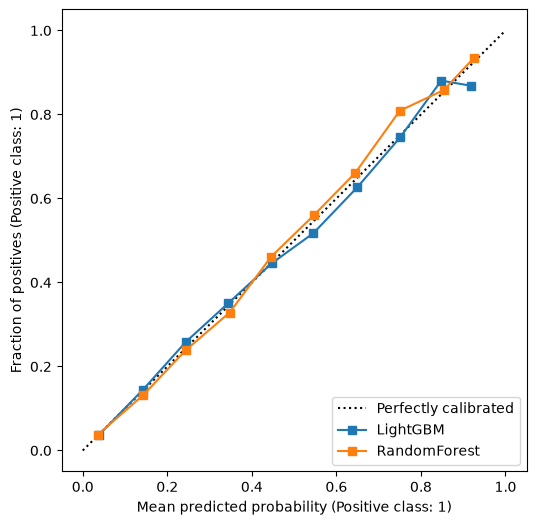

In [5]:
#mesurer la calibration du modèle
p_oof = cross_val_predict(meilleur_modele, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
p_rf = cross_val_predict(rf, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
fig, ax = plt.subplots(figsize=(6, 6)) 
CalibrationDisplay.from_predictions(y_train, p_oof, n_bins=10, name='LightGBM', ax=ax)
CalibrationDisplay.from_predictions(y_train, p_rf, n_bins=10, name='RandomForest', ax=ax)
plt.savefig(ROOT / 'reports' / 'figures' / 'fiabilite_avant.png', dpi=150)
plt.show()


In [6]:
#corriger : Platt et isotone
iso = CalibratedClassifierCV(meilleur_modele, method='isotonic', cv=5)
platt = CalibratedClassifierCV(meilleur_modele, method='sigmoid', cv=5)
p_iso = cross_val_predict(iso, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
p_platt = cross_val_predict(platt, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

def bilan(nom, p):
    return {
        'version': nom,
        'ECE': expected_calibration_error(y_train, p),
        'Brier': brier_score_loss(y_train, p),
        'PR-AUC': average_precision_score(y_train, p),
        'ROC-AUC': roc_auc_score(y_train, p),
    }

table_cal = pd.DataFrame([
    bilan('LightGBM brut', p_oof),
    bilan('+ Platt', p_platt),
    bilan('+ isotone', p_iso),
    bilan('Random Forest brute', p_rf),]).round(4)

table_cal


,version,ECE,Brier,PR-AUC,ROC-AUC
0,LightGBM brut,0.0042,0.0846,0.5791,0.8622
1,+ Platt,0.0048,0.0846,0.5786,0.8622
2,+ isotone,0.0040,0.0847,0.5764,0.8618
3,Random Forest brute,0.0062,0.0860,0.5683,0.8540


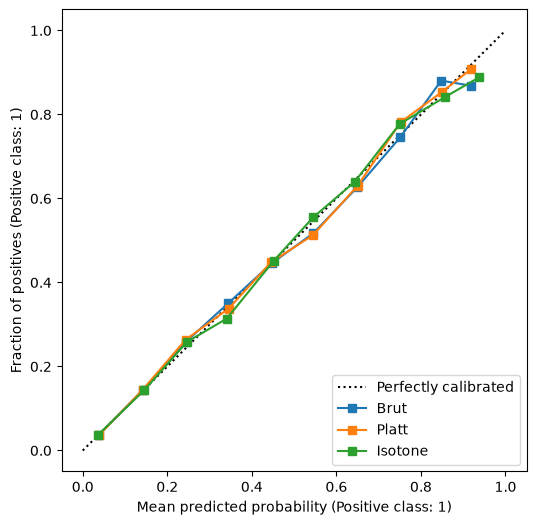

In [7]:
# diagramme de fiabilité après correction
fig, ax = plt.subplots(figsize=(6, 6))
for nom, p in [('Brut', p_oof), ('Platt', p_platt), ('Isotone', p_iso)]:
    CalibrationDisplay.from_predictions(y_train, p, n_bins=10, name=nom, ax=ax)
    
plt.savefig(ROOT / 'reports' / 'figures' / 'fiabilite_apres.png', dpi=150)
plt.show()

In [8]:
# compter les personnes bancarisées par pays
def comptage(p):
    return (pd.DataFrame({'pays': X_train['country'].to_numpy(),
        'reel': y_train.to_numpy(), 
        'predit': p}).groupby('pays')[['reel', 'predit']].sum())

resultats = {}

for nom, p in [('LightGBM brut', p_oof), ('LightGBM isotone', p_iso), ('Random Forest', p_rf)]:
    agg = comptage(p)
    agg['erreur_relative_%'] = ((agg['predit'] - agg['reel']) / agg['reel'] * 100).round(1)
    
    resultats[nom] = agg.round(0)
    
    print(nom)
    print(resultats[nom], '\n')

LightGBM brut
          reel  predit  erreur_relative_%
pays                                     
Kenya     1207  1204.0               -0.0
Rwanda     808   803.0               -1.0
Tanzania   490   491.0                0.0
Uganda     145   150.0                4.0 

LightGBM isotone
          reel  predit  erreur_relative_%
pays                                     
Kenya     1207  1210.0                0.0
Rwanda     808   804.0               -0.0
Tanzania   490   486.0               -1.0
Uganda     145   149.0                2.0 

Random Forest
          reel  predit  erreur_relative_%
pays                                     
Kenya     1207  1173.0               -3.0
Rwanda     808   787.0               -3.0
Tanzania   490   514.0                5.0
Uganda     145   181.0               25.0 



In [9]:
#seuil théorique et coût à 0,5 et à t*
from sklearn.metrics import confusion_matrix, make_scorer
from sklearn.model_selection import TunedThresholdClassifierCV
from inclusion_financiere.config import COST_FP, COST_FN
from inclusion_financiere.evaluate import cout_total

t_star = COST_FP / (COST_FP + COST_FN) # 0,5 / 5,5 ≈ 0,0909
y = y_train.to_numpy()

for nom, t in [('seuil 0,5', 0.5), ('seuil t*', t_star)]:
    y_pred = (p_iso >= t).astype(int)
    print(nom, round(t, 4))
    print(' matrice [[TN, FP], [FN, TP]] :', confusion_matrix(y, y_pred,
        labels=[0, 1]).tolist())
    print(' coût total :', cout_total(y, y_pred), ' | personnes contactées:', y_pred.sum())


cout_tous = cout_total(y, np.ones_like(y)) # on contacte tout le monde
cout_personne = cout_total(y, np.zeros_like(y)) # on ne contacte personne
cout_modele = cout_total(y, (p_iso >= t_star).astype(int))
print(f'Contacter tous : {cout_tous:.0f} | personne : {cout_personne:.0f} | modèle à t* : {cout_modele:.0f}')


seuil 0,5 0.5
 matrice [[TN, FP], [FN, TP]] : [[15842, 327], [1789, 861]]
 coût total : 9108.5  | personnes contactées: 1188
seuil t* 0.0909
 matrice [[TN, FP], [FN, TP]] : [[10998, 5171], [400, 2250]]
 coût total : 4585.5  | personnes contactées: 7421
Contacter tous : 8084 | personne : 13250 | modèle à t* : 4586


In [10]:
#seuil appris empiriquement
scorer_cout = make_scorer(lambda yt, yp: -cout_total(yt, yp))
tuned = TunedThresholdClassifierCV(iso, scoring=scorer_cout,
     cv=5, random_state=RANDOM_STATE).fit(X_train, y_train)

print('seuil empirique :', tuned.best_threshold_, '| seuil théorique :', t_star)


seuil empirique : 0.09945609945609946 | seuil théorique : 0.09090909090909091


In [11]:
#Q9.4 : et si un faux négatif ne coûte que 2 USD ?
t2 = COST_FP / (COST_FP + 2.0) # 0,5 / 2,5 = 0,2
y2 = (p_iso >= t2).astype(int)

print('nouveau seuil :', t2, '| personnes contactées :', y2.sum(), '(avant :', (p_iso >= t_star).sum(), ')')

nouveau seuil : 0.2 | personnes contactées : 4139 (avant : 7421 )


In [12]:
#figer la décision avant l’étape 10
seuil_retenu = float(t_star) # ou tuned.best_threshold_ si vous le justifiez

(ROOT / 'reports' / 'decision.json').write_text(json.dumps({'seuil_retenu':seuil_retenu}))
print(seuil_retenu)


0.09090909090909091
